# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 544.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 14.9 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
SEARCHES = {
    "arepa": [
        "arepa colombiana",
        "arepa paisa plato",
        "arepa de choclo",
    ],
    "empanada": [
        "empanada colombiana frita",
        "empanadas de carne y papa",
        "empanada colombiana con ají",
    ],
    "bunuelo": [
        "buñuelo colombiano",
        "buñuelos navideños colombia",
        "buñuelos fritos de queso",
    ],
}

SEARCHES

{'arepa': ['arepa colombiana', 'arepa paisa plato', 'arepa de choclo'],
 'empanada': ['empanada colombiana frita',
  'empanadas de carne y papa',
  'empanada colombiana con ají'],
 'bunuelo': ['buñuelo colombiano',
  'buñuelos navideños colombia',
  'buñuelos fritos de queso']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?

La arepa es plana, redonda y de color más claro o amarillo (a veces con marcas de la plancha). La empanada tiene forma de media luna, con borde sellado y un dorado más oscuro. El buñuelo es una bola pequeña, redonda e irregular, dorada y sin costura.
- ¿Qué imágenes incorrectas esperas encontrar?

Arepas rellenas que parecen sándwiches, empanadas horneadas de otros países, buñuelos de otros tipos (con azúcar o aplanados), fotos de menús, logos de restaurantes, platos combinados donde salen varias comidas a la vez.
- ¿Qué sesgo o *data leakage* podría aparecer?

Las fotos de cada clase suelen venir de contextos distintos. Por ejemplo, las empanadas suelen aparecer con ají o salsa y las arepas en platos de desayuno, así que el modelo podría aprender el fondo o el acompañante en lugar de la comida. Además, el buscador puede devolver la misma foto en varios sitios con otro tamaño o recorte, y esas casi duplicadas podrían terminar repartidas entre train y test.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== arepa ===
Buscando: 'arepa colombiana'
  Total guardadas hasta ahora: 32
Buscando: 'arepa paisa plato'
  Total guardadas hasta ahora: 52
Buscando: 'arepa de choclo'
  Total guardadas hasta ahora: 83

=== empanada ===
Buscando: 'empanada colombiana frita'
  Total guardadas hasta ahora: 33
Buscando: 'empanadas de carne y papa'
  Total guardadas hasta ahora: 60
Buscando: 'empanada colombiana con ají'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 87

=== bunuelo ===
Buscando: 'buñuelo colombiano'
  Total guardadas hasta ahora: 33
Buscando: 'buñuelos navideños colombia'
  Total guardadas hasta ahora: 63
Buscando: 'buñuelos fritos de queso'
  Total guardadas hasta ahora: 95

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'arepa': 83, 'bunuelo': 95, 'empanada': 87}

In [7]:
# Codigo Extra para añadir mas imagenes
SEARCHES_EXTRA = {
    "arepa": [
        "arepa antioqueña",
        "arepa blanca colombiana",
    ],
    "empanada": [
        "empanadas colombianas receta",
    ],
    "bunuelo": [
        "buñuelos colombianos receta",
    ],
}

download_image_dataset(SEARCHES_EXTRA, images_per_query=60)
count_images(RAW_DIR)


=== arepa ===
Buscando: 'arepa antioqueña'
  Total guardadas hasta ahora: 108
Buscando: 'arepa blanca colombiana'
  Total guardadas hasta ahora: 140

=== empanada ===
Buscando: 'empanadas colombianas receta'
  Total guardadas hasta ahora: 120

=== bunuelo ===
Buscando: 'buñuelos colombianos receta'
  Total guardadas hasta ahora: 128

Descarga terminada.


{'arepa': 140, 'bunuelo': 128, 'empanada': 120}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [9]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [15]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

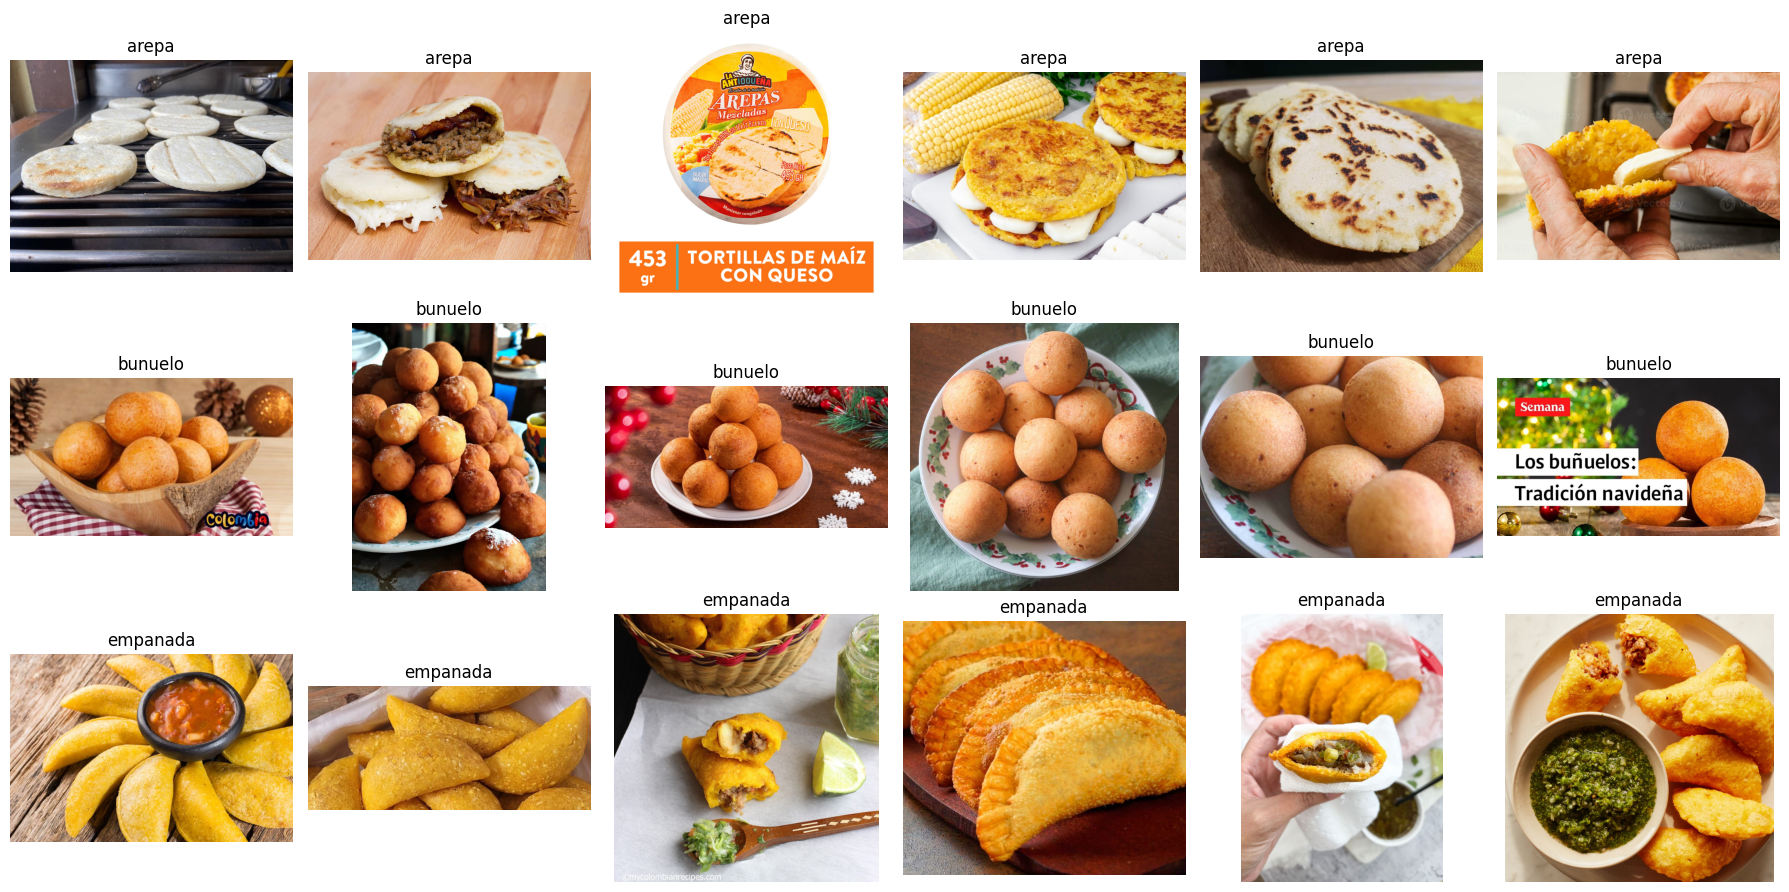

In [14]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

No se eliminaron imagenes ya que estas cuentan con una categorizacion no muy obvia, ademas, se ejecuto este bloque 5 veces y de esas solo se observaron alrededor de 2 o 3 imagenes con texto o logos, el resto es de comida lo suficientemente diferente o parecidas entre si sin ser muy obvia la diferencia.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [16]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'arepa': 98, 'bunuelo': 89, 'empanada': 84}
validation {'arepa': 21, 'bunuelo': 19, 'empanada': 18}
test {'arepa': 21, 'bunuelo': 20, 'empanada': 18}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

La idea central es que, si decides según el test, tus decisiones se ajustan a esas imágenes concretas, y el resultado en test deja de ser una medida honesta de cómo rendirá el modelo con datos nuevos. Por eso esas decisiones se toman con validation.

In [17]:
from google.colab import drive #Bloque de control en caso de desconexion de Colab
drive.mount("/content/drive")
!cp -r dataset "/content/drive/MyDrive/dataset_arepa_empanada_bunuelo"

Mounted at /content/drive


# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [18]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 271 files belonging to 3 classes.
Found 58 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
['arepa', 'bunuelo', 'empanada']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [19]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?

Espero que train_accuracy suba rápido, porque la base ya sabe extraer características de imágenes y solo se entrena la capa final.
- ¿qué señal en las curvas indicaría overfitting?

Una señal de overfitting sería que accuracy siga subiendo mientras val_accuracy se estanca o baja, y que val_loss empiece a subir.


Completa únicamente los espacios `TODO` del código siguiente.

In [20]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                      # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",                  # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 547ms/step - accuracy: 0.5277 - loss: 0.9821 - val_accuracy: 0.7414 - val_loss: 0.7857
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 277ms/step - accuracy: 0.7417 - loss: 0.7141 - val_accuracy: 0.8448 - val_loss: 0.5850
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 302ms/step - accuracy: 0.8266 - loss: 0.5462 - val_accuracy: 0.8621 - val_loss: 0.4713
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 283ms/step - accuracy: 0.8782 - loss: 0.4414 - val_accuracy: 0.8621 - val_loss: 0.4002
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 222ms/step - accuracy: 0.9004 - loss: 0.3573 - val_accuracy: 0.8793 - val_loss: 0.3572
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 230ms/step - accuracy: 0.9041 - loss: 0.3136 - val_accuracy: 0.8793 - val_loss: 0.3320
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 237ms/step - accuracy: 0.9262 - loss: 0.2713 - val_accuracy: 0.8966 - val_loss: 0.3143
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - accuracy: 0.9373 - loss: 0.2532 - val_accuracy: 0.8966 - val_loss

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

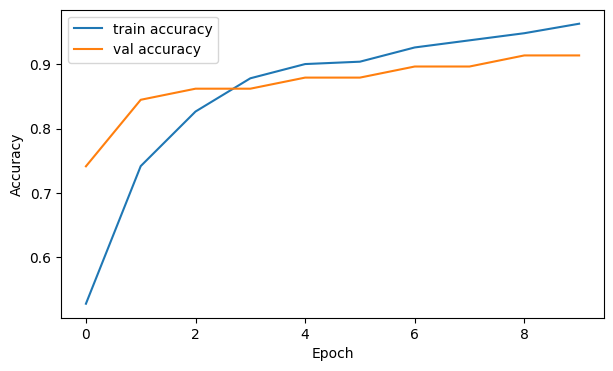

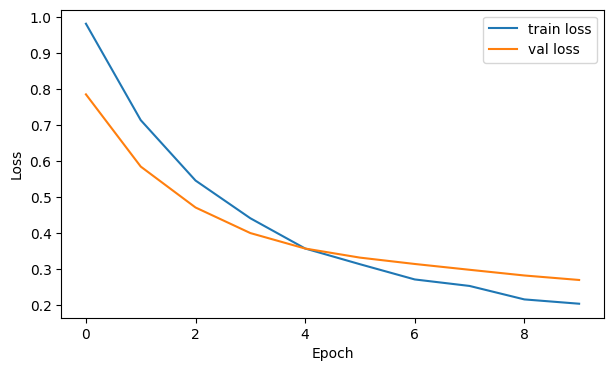

In [21]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [25]:
drive.mount("/content/drive")
model.save("/content/drive/MyDrive/modelo_congelado.keras") #Punto de guardado de modelo

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [26]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9831


              precision    recall  f1-score   support

       arepa      1.000     1.000     1.000        21
     bunuelo      1.000     0.950     0.974        20
    empanada      0.947     1.000     0.973        18

    accuracy                          0.983        59
   macro avg      0.982     0.983     0.982        59
weighted avg      0.984     0.983     0.983        59



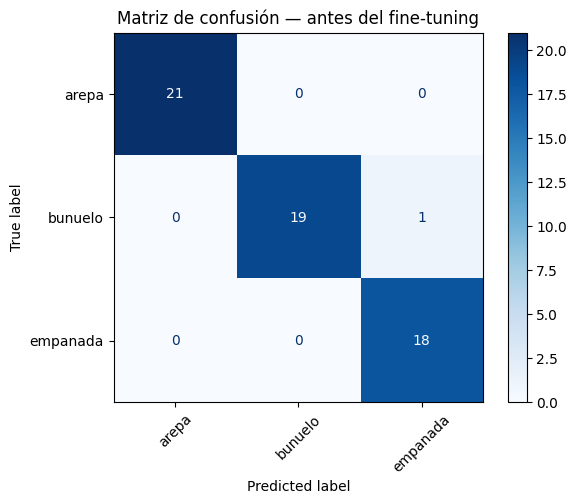

In [27]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?: La arepa, con precision, recall y F1 de 1.000. Es la más fácil de distinguir, por su forma plana y su color más claro.
2. ¿Cuál fue la principal confusión?: Un buñuelo clasificado como empanada. Es la única confusión que hay, y encaja con lo que esperábamos: las dos son fritas, doradas y de tono parecido.
3. ¿La accuracy global oculta algún problema por clase?: No de forma grave: los tres F1 están por encima de 0.97. Pero el soporte es muy pequeño (18 a 21 por clase), así que un solo error mueve el recall de una clase unos 5 puntos. La precision de empanada (0.947) baja porque “absorbió” ese error.
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?: Más imágenes, sobre todo para el test. Además, revisar esa imagen de buñuelo mal clasificada (puede ser ambigua o estar mal etiquetada) y comprobar si hay duplicados casi idénticos entre train y test.

test_acc_before = 0.9831

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [28]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

Usé N_UNFROZEN = 20, el valor sugerido por el taller (15 capas realmente entrenables, porque las BatchNormalization se mantuvieron congeladas). Con learning_rate=1e-5 y 8 épocas, val_loss bajó de 0.2698 a 0.2380 y val_accuracy pasó de 0.9138 a 0.9310. No comparé otros valores de N_UNFROZEN, así que no puedo afirmar que 20 sea el óptimo.

In [29]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 543ms/step - accuracy: 0.9631 - loss: 0.2117 - val_accuracy: 0.9310 - val_loss: 0.2660
Epoch 2/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - accuracy: 0.9520 - loss: 0.2040 - val_accuracy: 0.9310 - val_loss: 0.2603
Epoch 3/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 259ms/step - accuracy: 0.9742 - loss: 0.1713 - val_accuracy: 0.9310 - val_loss: 0.2549
Epoch 4/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 272ms/step - accuracy: 0.9483 - loss: 0.1638 - val_accuracy: 0.9310 - val_loss: 0.2497
Epoch 5/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 277ms/step - accuracy: 0.9520 - loss: 0.1811 - val_accuracy: 0.9310 - val_loss: 0.2462
Epoch 6/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - accuracy: 0.9594 - loss: 0.1597 - val_accuracy: 0.9310 - val_loss: 0.2414
Epoch 7/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 246ms/step - accuracy: 0.9668 - loss: 0.1576 - val_accuracy: 0.9310 - val_loss: 0.2397
Epoch 8/8
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 243ms/step - accuracy: 0.9668 - loss: 0.1505 - val_accuracy: 0.9310 - val_loss: 0.2380

# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [30]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9831
Después del fine-tuning: 0.9831
Diferencia              : +0.0000


              precision    recall  f1-score   support

       arepa      1.000     1.000     1.000        21
     bunuelo      1.000     0.950     0.974        20
    empanada      0.947     1.000     0.973        18

    accuracy                          0.983        59
   macro avg      0.982     0.983     0.982        59
weighted avg      0.984     0.983     0.983        59



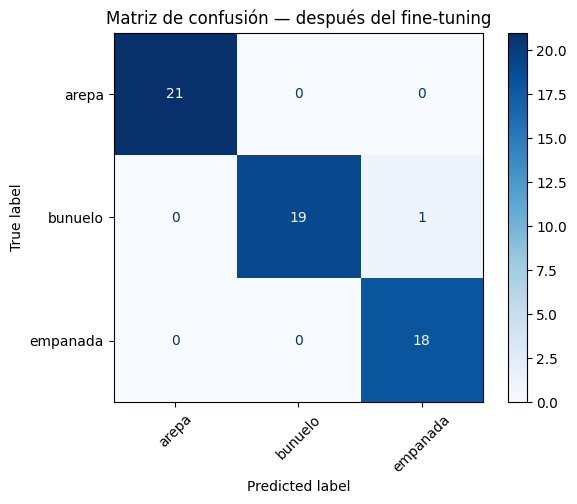

In [31]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

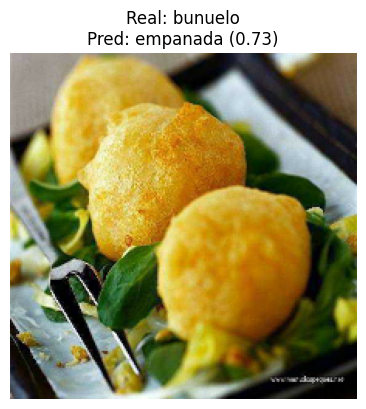

In [32]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

El Test al tener un unico error, se agrega esta celda para usar los errores de validation para poder completar los 5 errores requeridos

5 errores en total



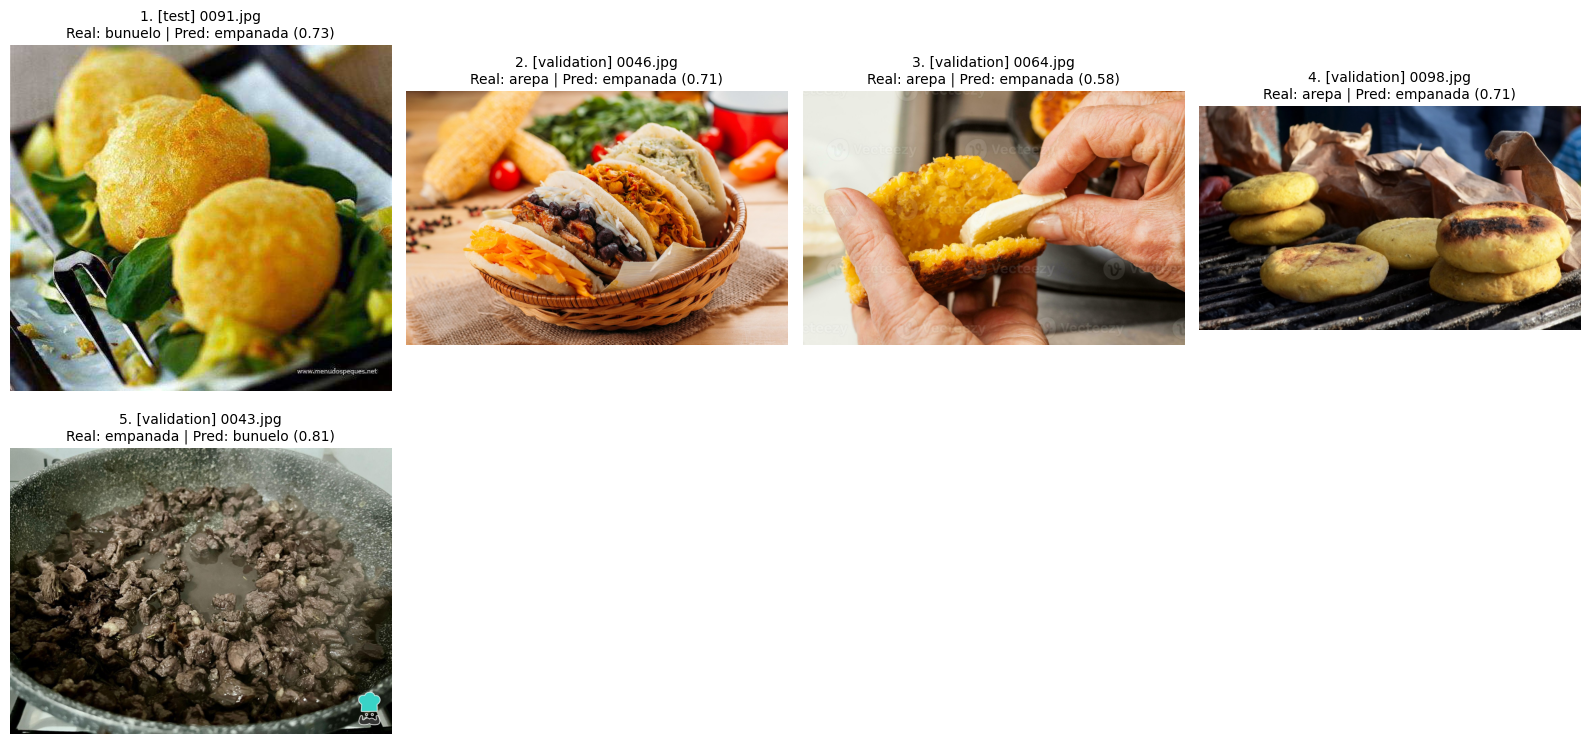

In [33]:
def collect_mistakes(split_name, ds): #
    root = SPLIT_DIR / split_name
    paths = []
    for c in class_names:
        paths += sorted((root / c).glob("*.jpg"))

    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    y_pred = probs.argmax(axis=1)

    assert len(paths) == len(y_true), "No coincide el número de imágenes"
    assert all(p.parent.name == class_names[t] for p, t in zip(paths, y_true)), \
        "El orden de los archivos no coincide con las etiquetas"

    return [(paths[i], int(y_true[i]), int(y_pred[i]), float(probs[i][y_pred[i]]))
            for i in range(len(paths)) if y_true[i] != y_pred[i]]

mistakes = (
    [("test", *m) for m in collect_mistakes("test", test_ds)] +
    [("validation", *m) for m in collect_mistakes("validation", val_ds)]
)

print(len(mistakes), "errores en total\n")
plt.figure(figsize=(16, 4 * int(np.ceil(len(mistakes) / 4))))
for i, (split, path, t, p, conf) in enumerate(mistakes):
    ax = plt.subplot(int(np.ceil(len(mistakes) / 4)), 4, i + 1)
    ax.imshow(Image.open(path))
    ax.set_title(f"{i+1}. [{split}] {path.name}\nReal: {class_names[t]} | Pred: {class_names[p]} ({conf:.2f})",
                 fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 (test, 0091) | bunuelo | empanada (0.73) | Fondo engañoso: plato de restaurante con hojas verdes y unas pinzas. Las piezas son doradas e irregulares, parecidas a una fritura de empanada. Tiene marca de agua de una página web. | Agregar más buñuelos en contextos variados (platos servidos, con acompañantes) y evitar imágenes con marca de agua. |
| 2 (val, 0046) | arepa | empanada (0.71) | Clase visualmente similar: son arepas rellenas, abiertas por un lado y con el relleno visible, por lo que parecen bolsillos o sándwiches. Además hay muchos elementos de fondo (maíz, verduras, olla roja). | Separar las arepas rellenas o agregar más ejemplos de ese tipo, y decidir si cuentan como "arepa". |
| 3 (val, 0064) | arepa | empanada (0.58) | Primer plano con manos partiendo una arepa dorada y sacando queso. La forma completa no se ve (recorte y oclusión) y se ve el relleno. Tiene marcas de agua de un banco de imágenes. | Incluir más fotos de arepas enteras y de arepas con queso, y descartar fotos con marca de agua. |
| 4 (val, 0098) | arepa | empanada (0.71) | Error razonable del modelo: arepas amarillas gruesas sobre una parrilla, con zonas tostadas y un color dorado cercano al de una fritura. El fondo (papel y parrilla) es poco habitual. | Agregar más arepas de maíz amarillo y asadas, con mayor variedad de fondos. |
| 5 (val, 0043) | empanada | bunuelo (0.81) | Etiqueta incorrecta o dato inválido: la imagen muestra carne picada cocinándose en una sartén (el relleno) y no una empanada. No pertenece a ninguna de las tres clases. | Eliminarla del dataset y hacer una limpieza semántica más rigurosa. |


Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

## Conclusión

**1. ¿Qué aprendí al construir el dataset?**
Que la calidad del dataset depende mucho de los términos de búsqueda: agregar "colombiano" a las consultas trajo imágenes más relevantes que los términos genéricos, y mejorar las búsquedas funcionó mejor que aumentar `max_results`. También aprendí que validar que las imágenes se puedan abrir no basta: una imagen técnicamente válida puede no servir como dato de entrenamiento. El dataset final quedó con 388 imágenes (140 arepas, 128 buñuelos y 120 empanadas), repartidas en 271 para train, 58 para validation y 59 para test.

**2. ¿Cuál fue el principal problema de calidad?**
Durante la inspección visual no vi problemas evidentes, pero el análisis de errores mostró lo contrario: hay imágenes que no corresponden a la clase (una "empanada" que solo muestra carne picada en una sartén), arepas rellenas que se parecen a empanadas o sándwiches, y fotos con marcas de agua o texto. Además, cada comida aparece en contextos distintos, lo que puede introducir sesgo de fondo. [Si no revisaste duplicados casi idénticos, agrega: "No revisé duplicados casi idénticos, así que no puedo descartar que haya alguno entre train y test."]

**3. ¿Cuánto cambió el desempeño después del fine-tuning?**
En validation, `val_loss` bajó de 0.2698 a 0.2380 y `val_accuracy` pasó de 0.9138 a 0.9310 (una imagen más acertada de 58). En test la accuracy no cambió: 0.9831 antes y después (58 de 59), con la misma matriz de confusión y el mismo error (un buñuelo clasificado como empanada). La diferencia fue de +0.0000.

**4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?**
Ayudó muy poco: la mejora en validation es pequeña y en test no hubo cambio. Creo que el motivo es que el modelo con la base congelada ya estaba muy cerca del máximo posible para este dataset, así que quedaba poco margen de mejora. Además, con 58 y 59 imágenes cada imagen vale cerca de 1.7 puntos de accuracy, por lo que estas diferencias están dentro del ruido y no se pueden interpretar como una mejora real. Que el mismo buñuelo siga mal clasificado sugiere que el problema está en la imagen (fondo, ambigüedad o etiqueta dudosa) y no en la falta de ajuste de la base.

**5. ¿Qué mejoraría primero: datos, entrenamiento o arquitectura?**
Los datos. Primero haría una limpieza semántica más rigurosa (eliminar imágenes que no pertenecen a la clase y revisar duplicados), decidiría cómo tratar las arepas rellenas, y agregaría más imágenes en contextos variados, sobre todo para tener un conjunto de test más grande y una evaluación más fiable. Solo después probaría cambios en el entrenamiento o en la arquitectura, porque los errores observados parecen venir de los datos y no del modelo.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

Usando a Claude, se optimizo este bloque para que entre un diccionario con links junto a otras imagenes que no pertenecen a ninguna de las clases

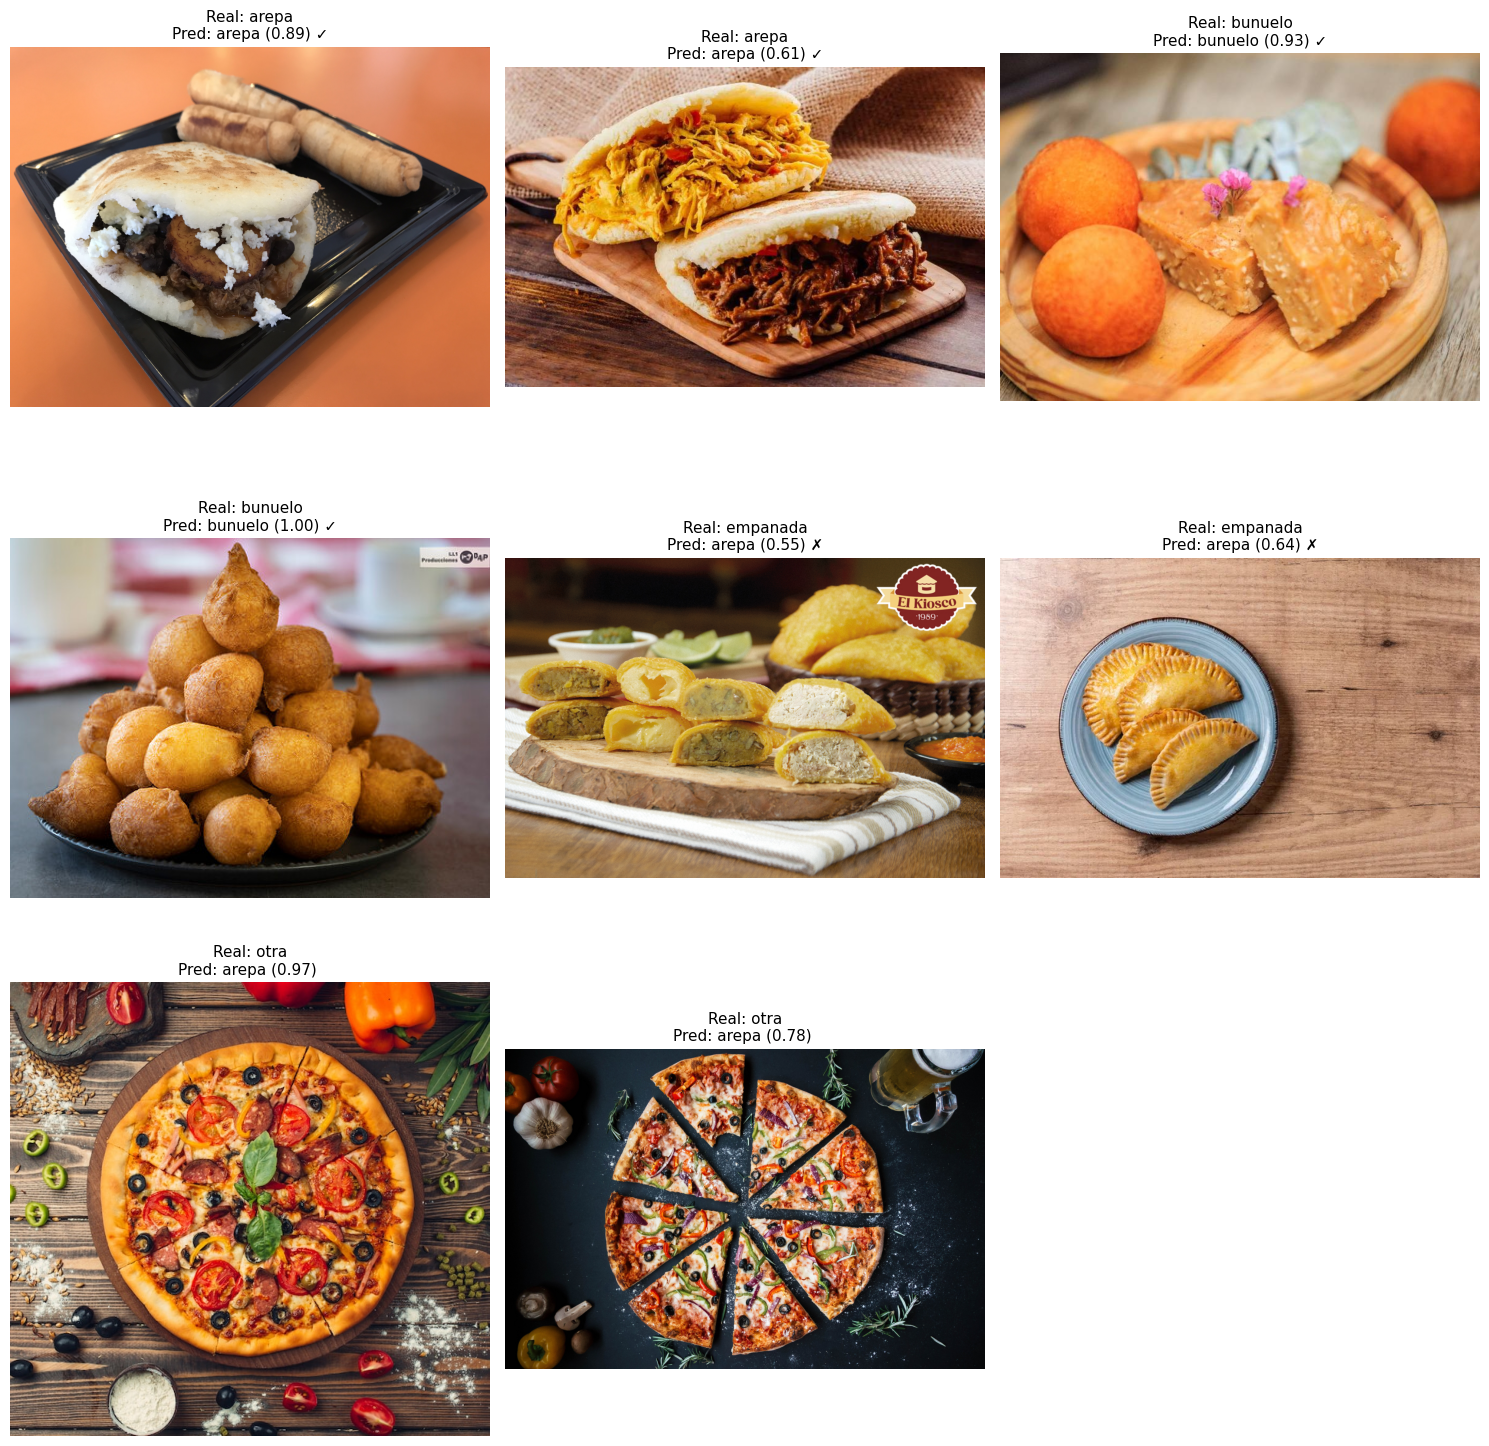

Aciertos en imágenes externas: 4/6 = 66.67%


In [39]:
EXTERNAL_URLS = {
    "arepa":    ["https://thumb.wikimedia.org/wikipedia/commons/thumb/9/9b/Arepa_y_tequeños.JPG/3840px-Arepa_y_tequeños.JPG", "https://i.pinimg.com/736x/96/ec/b9/96ecb964f4d5242b1fd9aa7abc1ebc82.jpg"],
    "bunuelo":  ["https://estaticos.elcolombiano.com/binrepository/848x565/34c0/780d565/none/11101/BBPC/cenatilla-y-bunuelos-22_46796896_20241219200751.jpg", "https://i.blogs.es/f169dc/bunuelos_colombianos/450_1000.jpg"],
    "empanada": ["https://cdnx.jumpseller.com/el-kiosco-golosinas/image/65179250/EMPANADAS_20ABIERTAS.jpg", "https://st2.depositphotos.com/2593537/90310/i/450/depositphotos_903102730-stock-photo-homemade-golden-baked-empanadas-crimped.jpg"],
    # Opcional: algo que no sea ninguna de las 3 clases (para ver qué hace el modelo)
    "otra":   ["https://img.magnific.com/foto-gratis/pizza-pizza-rellena-tomates-salami-aceitunas_140725-1200.jpg", "https://thumb.wikimedia.org/wikipedia/commons/thumb/9/91/Pizza-3007395.jpg/3840px-Pizza-3007395.jpg"],
} #Las "otra" son pizzas (Se estima que las reconozca como arepas por su forma)

HEADERS = {"User-Agent": "Mozilla/5.0"}

def load_image(url):
    if not url.startswith(("http://", "https://")):
        url = "https://" + url            # corrige links sin protocolo
    r = requests.get(url, headers=HEADERS, timeout=10)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

# 1) Descargar las imágenes (las que fallen se saltan y se avisa)
items = []
for true_class, urls in EXTERNAL_URLS.items():
    for url in urls:
        if "..." in url:
            continue
        try:
            items.append((true_class, url, load_image(url)))
        except Exception as e:
            print(f"No se pudo descargar ({type(e).__name__}): {url}")

assert items, "No hay imágenes: revisa los links en EXTERNAL_URLS"

# 2) Predecir todas juntas
x = np.stack([np.array(img.resize(IMG_SIZE), dtype="float32") for _, _, img in items])
probs = model.predict(x, verbose=0)

# 3) Mostrar resultados
cols = 3
rows = int(np.ceil(len(items) / cols))
plt.figure(figsize=(5 * cols, 5 * rows))
correct = total = 0
for i, ((true_class, url, img), p) in enumerate(zip(items, probs)):
    pred = class_names[p.argmax()]
    if true_class in class_names:
        ok = pred == true_class
        mark = "✓" if ok else "✗"
        correct += ok
        total += 1
    else:
        mark = ""
    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)
    ax.set_title(f"Real: {true_class}\nPred: {pred} ({p.max():.2f}) {mark}", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

if total:
    print(f"Aciertos en imágenes externas: {correct}/{total} = {correct/total:.2%}")

**Resultados**

Probé el modelo con 8 imágenes que no están en el dataset: 2 arepas, 2 buñuelos, 2 empanadas y 2 pizzas (ninguna de las tres clases).

- **Aciertos:** 4 de 6 imágenes de las clases del problema (66.7 %). Las arepas y los buñuelos se clasificaron bien, incluidas arepas rellenas.
- **Fallos:** las dos empanadas se clasificaron como arepa. Una era una empanada horneada de borde rizado, un tipo poco presente en el dataset (casi todo eran empanadas colombianas fritas).
- **Imágenes de otra clase:** las dos pizzas se clasificaron como arepa, con confianza 0.97 y 0.78. Como el modelo termina en un softmax de solo 3 clases, siempre elige una de ellas aunque la imagen no pertenezca a ninguna, y una confianza alta no garantiza que la predicción sea correcta.
- **Interpretación:** la accuracy en estas imágenes (66.7 %) es mucho menor que la del test (98.3 %). Con solo 6 imágenes no es una medida fiable, pero sugiere que el test sobreestima la generalización, porque viene de las mismas búsquedas y estilos que el entrenamiento. Para mejorarlo agregaría más variedad (empanadas horneadas, distintos fondos y fuentes) y una clase "otra" para imágenes que no pertenecen a ninguna.

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

## Cierre conceptual

La diferencia entre las tres estrategias está en **qué parámetros se aprenden** y en **de dónde viene el conocimiento inicial**.

**1. Feature extraction / transfer learning con base congelada**
El conocimiento inicial viene de ImageNet: EfficientNetB0 ya fue entrenada por otros con más de un millón de imágenes, así que sus capas ya detectan bordes, texturas, formas y partes de objetos. Al congelar la base (`base_model.trainable = False`) esos pesos, 4.049.571, no cambian. Lo único que se aprende con mis imágenes es la nueva cabeza: la capa `Dense` final, con 1280 × 3 + 3 = 3,843 parámetros, que aprende a combinar las características que ya extrae la base para separar arepa, buñuelo y empanada. Es el método más barato y el que menos riesgo tiene de sobreajustar con pocos datos. En mi caso, con solo 271 imágenes de entrenamiento, llegó a 0.914 de accuracy en validation.

**2. Fine-tuning**
Parte del mismo conocimiento de ImageNet y de la cabeza ya entrenada, pero además deja que se ajusten las últimas capas de la base (en mi caso, 15 capas entrenables, con las `BatchNormalization` congeladas) usando una tasa de aprendizaje muy baja (`1e-5`). Aquí se aprenden la cabeza y esas capas finales, que son las más específicas y se pueden adaptar a las características de estas comidas, mientras que las capas iniciales (bordes y texturas generales) se quedan como están. La tasa de aprendizaje baja es para no destruir lo que la red ya sabía. Tiene más capacidad de adaptación, pero también más riesgo de sobreajustar con pocos datos. En mi experimento mejoró un poco en validation (`val_loss` de 0.2698 a 0.2380) y no cambió la accuracy en test (0.9831).

**3. Entrenar una CNN desde cero**
Aquí no hay conocimiento previo: todos los pesos empiezan con valores aleatorios y la red tiene que aprender todo (desde los bordes más simples hasta las formas completas) únicamente con mi dataset. Se aprenden todos los parámetros de la red, que pueden ser de cientos de miles a millones. Con solo 388 imágenes, eso casi seguro daría sobreajuste y un rendimiento bastante peor, porque esos pocos datos no bastan para enseñar todo eso. Es la opción que solo vale la pena con muchos datos o con imágenes muy distintas a las de ImageNet. No la probé en este taller, así que esto es una explicación conceptual y no un resultado experimental.

| | Conocimiento inicial | Qué se aprende | Datos que necesita |
|---|---|---|---|
| Base congelada | ImageNet | Solo la cabeza (3,843 parámetros) | Pocos |
| Fine-tuning | ImageNet + cabeza ya entrenada | Cabeza + capas finales de la base | Pocos o moderados |
| Desde cero | Ninguno (pesos aleatorios) | Todos los parámetros | Muchos |

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |